# Bank Customer Segmentation with K-Means

In this project, I group 1,000 bank customers (650 Retail and 350 Wholesale) into segments, name the segments, and suggest a campaign idea and a KPI for each one.

**Business question:** How can a bank understand its different types of customers and make more relevant offers to them?

> **Note:** The dataset is synthetic, not real bank data. This is a practice project, so the results should not be treated as findings about an actual bank.

**Steps:** (1) explore the customers, (2) find segments with K-Means, (3) name the segments, (4) suggest a campaign and a KPI for each segment.

## Part 1. Understand the customers

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("banking_customer_segmentation.csv")
print("Dataset shape:", df.shape)
df.head()

Dataset shape: (1000, 13)


,customer_id,customer_type,age_or_business_years,monthly_income_or_revenue_amd,average_balance_amd,monthly_transaction_count,monthly_transaction_volume_amd,loan_outstanding_amd,product_count,digital_transactions_pct,tenure_months,last_campaign_response,next_90d_revenue_amd
0,R0001,Retail,55,1064618,3239028,41,605808,3874889,3,100,113,0,40745
1,R0002,Retail,74,87751,207132,8,54757,0,2,52,54,0,1693
2,R0003,Retail,36,608827,1113428,14,741562,0,1,59,15,0,19254
3,R0004,Retail,63,818234,620189,14,1597635,0,1,56,41,0,20887
4,R0005,Retail,31,90235,130957,6,109825,18439,1,8,6,1,2569


In [2]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 13 columns):
 #   Column                          Non-Null Count  Dtype
---  ------                          --------------  -----
 0   customer_id                     1000 non-null   str  
 1   customer_type                   1000 non-null   str  
 2   age_or_business_years           1000 non-null   int64
 3   monthly_income_or_revenue_amd   1000 non-null   int64
 4   average_balance_amd             1000 non-null   int64
 5   monthly_transaction_count       1000 non-null   int64
 6   monthly_transaction_volume_amd  1000 non-null   int64
 7   loan_outstanding_amd            1000 non-null   int64
 8   product_count                   1000 non-null   int64
 9   digital_transactions_pct        1000 non-null   int64
 10  tenure_months                   1000 non-null   int64
 11  last_campaign_response          1000 non-null   int64
 12  next_90d_revenue_amd            1000 non-null   int64
dtypes: int64(11), s

In [3]:
print("Missing values:", df.isna().sum().sum())
print("Duplicate customer_id:", df["customer_id"].duplicated().sum())
df["customer_type"].value_counts()

Missing values: 0
Duplicate customer_id: 0


customer_type
Retail       650
Wholesale    350
Name: count, dtype: int64

In [4]:
retail = df[df["customer_type"] == "Retail"].copy()
wholesale = df[df["customer_type"] == "Wholesale"].copy()
print("Retail:", retail.shape)
print("Wholesale:", wholesale.shape)

Retail: (650, 13)
Wholesale: (350, 13)


In [5]:
features = [
    "monthly_income_or_revenue_amd",
    "average_balance_amd",
    "monthly_transaction_count",
    "monthly_transaction_volume_amd",
    "loan_outstanding_amd",
    "product_count",
    "digital_transactions_pct",
]
print("ALL CUSTOMERS")
display(df[features].describe().round(2))
print("RETAIL")
display(retail[features].describe().round(2))
print("WHOLESALE")
display(wholesale[features].describe().round(2))

ALL CUSTOMERS


,monthly_income_or_revenue_amd,average_balance_amd,monthly_transaction_count,monthly_transaction_volume_amd,loan_outstanding_amd,product_count,digital_transactions_pct
count,1.000000e+03,1.000000e+03,1000.00,1.000000e+03,1.000000e+03,1000.00,1000.00
mean,1.411862e+07,3.364656e+07,41.87,1.792961e+07,1.520847e+07,2.38,59.52
std,4.571192e+07,1.277706e+08,48.20,6.056190e+07,6.326691e+07,0.94,28.72
min,6.434400e+04,2.455300e+04,1.00,2.696800e+04,0.000000e+00,1.00,0.00
25%,3.487872e+05,4.931135e+05,12.00,4.120450e+05,0.000000e+00,2.00,35.00
50%,9.764420e+05,1.917668e+06,27.00,1.291902e+06,0.000000e+00,2.00,65.00
75%,4.851548e+06,9.483766e+06,48.00,6.188220e+06,2.169717e+06,3.00,84.00
max,4.513016e+08,1.516457e+09,256.00,7.015257e+08,7.093150e+08,4.00,100.00


RETAIL


,monthly_income_or_revenue_amd,average_balance_amd,monthly_transaction_count,monthly_transaction_volume_amd,loan_outstanding_amd,product_count,digital_transactions_pct
count,650.00,650.00,650.00,650.00,650.00,650.00,650.00
mean,861553.83,2102399.84,26.19,1145300.26,893652.07,2.34,59.28
std,1050402.39,3339874.31,20.36,1618584.60,1600813.26,0.95,28.83
min,64344.00,24553.00,1.00,26968.00,0.00,1.00,0.00
25%,247631.50,296913.25,8.00,287921.75,0.00,2.00,36.00
50%,476229.50,835140.00,20.00,590885.50,0.00,2.00,65.00
75%,971883.50,2258386.75,38.00,1311563.75,1059287.00,3.00,83.00
max,6679665.00,25939816.00,82.00,13100195.00,11206235.00,4.00,100.00


WHOLESALE


,monthly_income_or_revenue_amd,average_balance_amd,monthly_transaction_count,monthly_transaction_volume_amd,loan_outstanding_amd,product_count,digital_transactions_pct
count,3.500000e+02,3.500000e+02,350.00,3.500000e+02,3.500000e+02,350.00,350.00
mean,3.873889e+07,9.222858e+07,70.98,4.910048e+07,4.179314e+07,2.44,59.95
std,7.102164e+07,2.035068e+08,67.62,9.484105e+07,1.017959e+08,0.93,28.55
min,6.170360e+05,3.361900e+05,5.00,2.979990e+05,0.000000e+00,1.00,0.00
25%,4.035950e+06,6.347670e+06,15.00,4.288774e+06,0.000000e+00,2.00,33.00
50%,1.082578e+07,1.664789e+07,43.00,1.348405e+07,0.000000e+00,3.00,66.00
75%,3.658711e+07,7.819548e+07,101.00,3.970202e+07,3.218526e+07,3.00,85.00
max,4.513016e+08,1.516457e+09,256.00,7.015257e+08,7.093150e+08,4.00,100.00


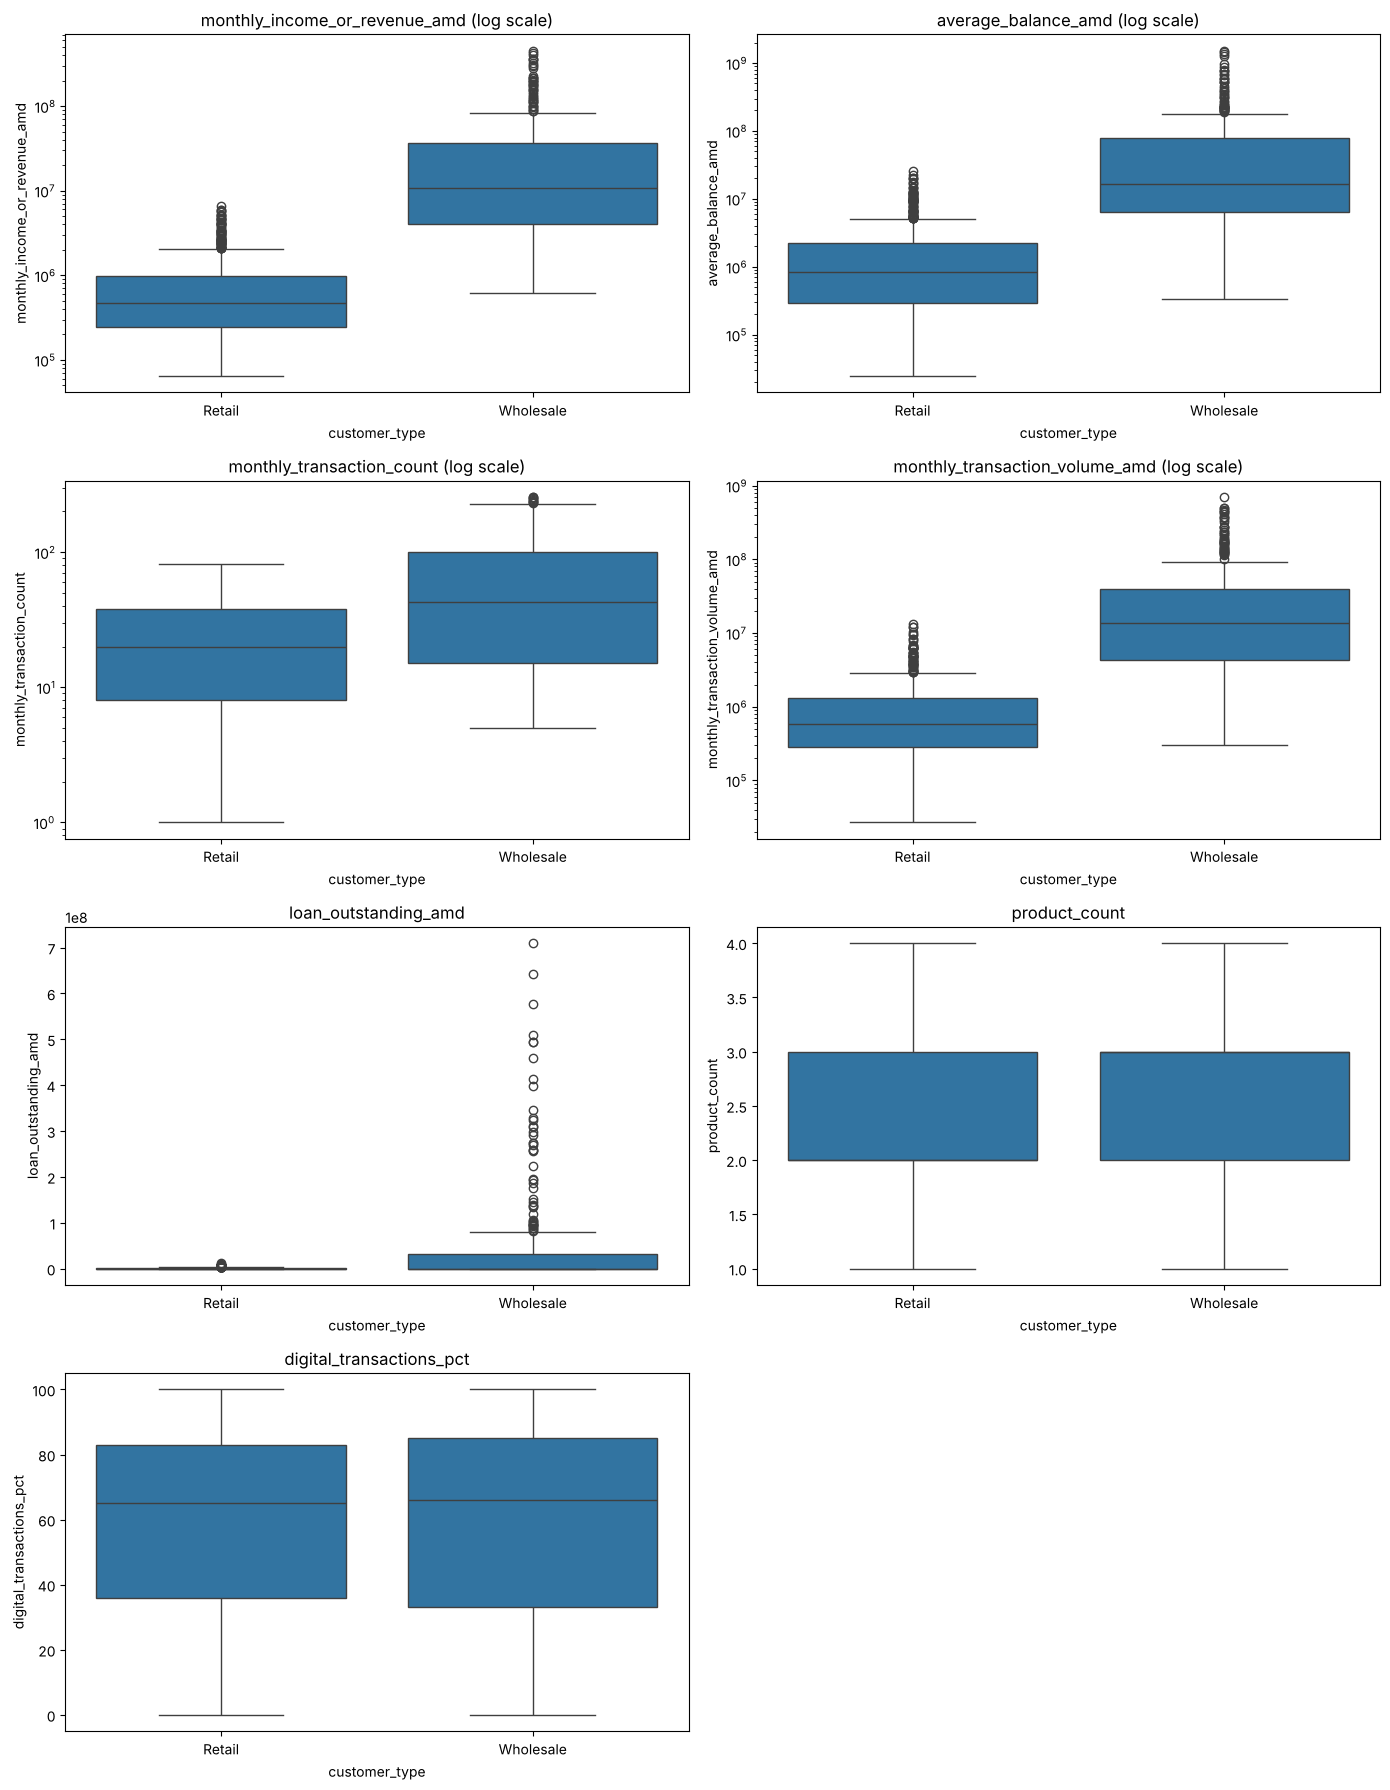

In [6]:
log_cols = [
    "monthly_income_or_revenue_amd", "average_balance_amd",
    "monthly_transaction_count", "monthly_transaction_volume_amd",
]
fig, axes = plt.subplots(4, 2, figsize=(14, 18))
axes = axes.flatten()
for i, col in enumerate(features):
    sns.boxplot(data=df, x="customer_type", y=col, ax=axes[i])
    axes[i].set_title(col + (" (log scale)" if col in log_cols else ""))
    if col in log_cols:
        axes[i].set_yscale("log")
axes[-1].set_visible(False)
plt.tight_layout()
plt.show()

**What I see in Part 1**

- Wholesale customers are much bigger than Retail customers in income/revenue, balance and transaction value. That is why I look at them separately.
- The data is skewed: a few very large customers pull the average up. For example, the average balance of all customers is 33.6M AMD, but the median is only 1.9M AMD.
- Customers who look more valuable and active have a high balance, many transactions and more products.
- I do not use `next_90d_revenue_amd`, `last_campaign_response` and `tenure_months` to create the groups. I use them later to describe the groups.

## Part 2. Discover customer segments

In [7]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

X_retail = retail[features]
X_wholesale = wholesale[features]

X_retail_scaled = StandardScaler().fit_transform(X_retail)
X_wholesale_scaled = StandardScaler().fit_transform(X_wholesale)
print(X_retail_scaled.shape, X_wholesale_scaled.shape)

(650, 7) (350, 7)


,Retail,Wholesale
k,,
2,0.478,0.563
3,0.326,0.323
4,0.310,0.352
5,0.319,0.378


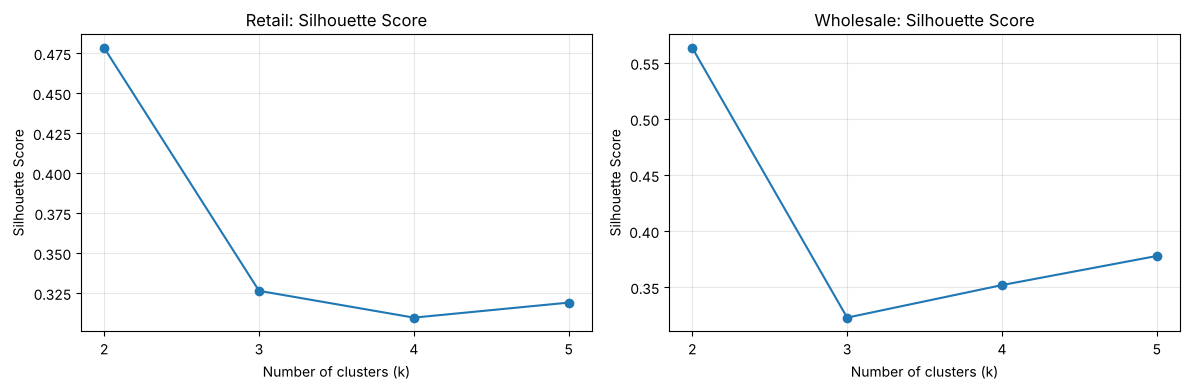

In [8]:
k_values = [2, 3, 4, 5]
scores = {"Retail": [], "Wholesale": []}

for name, X in [("Retail", X_retail_scaled), ("Wholesale", X_wholesale_scaled)]:
    for k in k_values:
        labels = KMeans(n_clusters=k, random_state=42, n_init=10).fit_predict(X)
        scores[name].append(silhouette_score(X, labels))

sil = pd.DataFrame(scores, index=pd.Index(k_values, name="k")).round(3)
display(sil)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, name in zip(axes, ["Retail", "Wholesale"]):
    ax.plot(k_values, scores[name], marker="o")
    ax.set_title(f"{name}: Silhouette Score")
    ax.set_xlabel("Number of clusters (k)")
    ax.set_ylabel("Silhouette Score")
    ax.set_xticks(k_values)
    ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

**Choosing the number of groups (k)**

The Silhouette Score shows how clearly the groups are separated. It is highest with 2 groups (Retail 0.478, Wholesale 0.563).

I still use 3 groups, on my mentor's advice. With 2 groups, customers are split only into big and small. With 3 groups, I also get a separate digital group that can have its own campaign.

The cost of this choice: with 3 groups the score is only around 0.33 (Retail 0.326, Wholesale 0.323), so the groups overlap somewhat.

In [9]:
kmeans_retail = KMeans(n_clusters=3, random_state=42, n_init=10)
kmeans_wholesale = KMeans(n_clusters=3, random_state=42, n_init=10)

retail["Cluster"] = kmeans_retail.fit_predict(X_retail_scaled)
wholesale["Cluster"] = kmeans_wholesale.fit_predict(X_wholesale_scaled)

print("Retail:");    print(retail["Cluster"].value_counts().sort_index())
print("\nWholesale:"); print(wholesale["Cluster"].value_counts().sort_index())

Retail:
Cluster
0     80
1    251
2    319
Name: count, dtype: int64

Wholesale:
Cluster
0     34
1    149
2    167
Name: count, dtype: int64


## Part 3. Understand and name the clusters

In [10]:
# Add the Cluster column to the original dataset
df["Cluster"] = pd.concat([retail["Cluster"], wholesale["Cluster"]]).astype(int)
print("Customers without a cluster:", df["Cluster"].isna().sum())

profile_cols = features + ["tenure_months"]
print("RETAIL CLUSTER PROFILES")
display(retail.groupby("Cluster")[profile_cols].mean().round(2))
print("WHOLESALE CLUSTER PROFILES")
display(wholesale.groupby("Cluster")[profile_cols].mean().round(2))

Customers without a cluster: 0
RETAIL CLUSTER PROFILES


,monthly_income_or_revenue_amd,average_balance_amd,monthly_transaction_count,monthly_transaction_volume_amd,loan_outstanding_amd,product_count,digital_transactions_pct,tenure_months
Cluster,,,,,,,,
0,3185811.51,9125436.89,61.52,4256997.94,2666523.94,3.11,55.76,64.26
1,250684.00,409465.94,8.47,350776.38,66425.61,1.73,32.47,73.37
2,759320.95,1673194.35,31.28,990095.49,1099934.50,2.62,81.27,71.73


WHOLESALE CLUSTER PROFILES


,monthly_income_or_revenue_amd,average_balance_amd,monthly_transaction_count,monthly_transaction_volume_amd,loan_outstanding_amd,product_count,digital_transactions_pct,tenure_months
Cluster,,,,,,,,
0,2.222145e+08,5.662474e+08,182.03,2.843353e+08,1.994579e+08,3.09,60.26,75.29
1,6.037769e+06,1.039762e+07,19.79,7.428765e+06,3.064403e+06,1.88,36.48,72.21
2,3.056102e+07,6.873259e+07,94.04,3.838851e+07,4.424811e+07,2.81,80.83,76.92


The cluster numbers are just labels. Retail cluster 0 is **not** the same group as Wholesale cluster 0. So I name the groups by their profile: the highest average income/revenue is the top group, the lowest is the passive group, and the middle one is the digital group (about 81% digital transactions).

In [11]:
retail_names = {"top": "Premium Active", "mid": "Digital Core", "low": "Passive"}
wholesale_names = {"top": "Key Accounts", "mid": "Digital Mid-size", "low": "Low-Activity"}

def add_names(d, names):
    order = d.groupby("Cluster")["monthly_income_or_revenue_amd"].mean().sort_values().index
    mapping = {order[0]: names["low"], order[1]: names["mid"], order[2]: names["top"]}
    return d["Cluster"].map(mapping)

retail["Segment"] = add_names(retail, retail_names)
wholesale["Segment"] = add_names(wholesale, wholesale_names)
df["Segment"] = pd.concat([retail["Segment"], wholesale["Segment"]])

def summary(d):
    g = d.groupby(["Cluster", "Segment"])
    out = pd.DataFrame({
        "clients": g.size(),
        "share_of_clients_%": g.size() / len(d) * 100,
        "share_of_90d_revenue_%": g["next_90d_revenue_amd"].sum() / d["next_90d_revenue_amd"].sum() * 100,
        "avg_90d_revenue_amd": g["next_90d_revenue_amd"].mean(),
        "past_campaign_response_%": g["last_campaign_response"].mean() * 100,
    })
    return out.round(1)

print("RETAIL");    display(summary(retail))
print("WHOLESALE"); display(summary(wholesale))
print("Overall past campaign response, %:")
print((df.groupby("customer_type")["last_campaign_response"].mean() * 100).round(1))

RETAIL


,,clients,share_of_clients_%,share_of_90d_revenue_%,avg_90d_revenue_amd,past_campaign_response_%
Cluster,Segment,,,,,
0,Premium Active,80,12.3,49.8,127106.9,28.7
1,Passive,251,38.6,8.2,6673.8,9.6
2,Digital Core,319,49.1,42.0,26919.3,20.1


WHOLESALE


,,clients,share_of_clients_%,share_of_90d_revenue_%,avg_90d_revenue_amd,past_campaign_response_%
Cluster,Segment,,,,,
0,Key Accounts,34,9.7,57.9,8161817.3,17.6
1,Low-Activity,149,42.6,5.3,171028.5,12.8
2,Digital Mid-size,167,47.7,36.8,1057477.9,24.6


Overall past campaign response, %:
customer_type
Retail       17.1
Wholesale    18.9
Name: last_campaign_response, dtype: float64


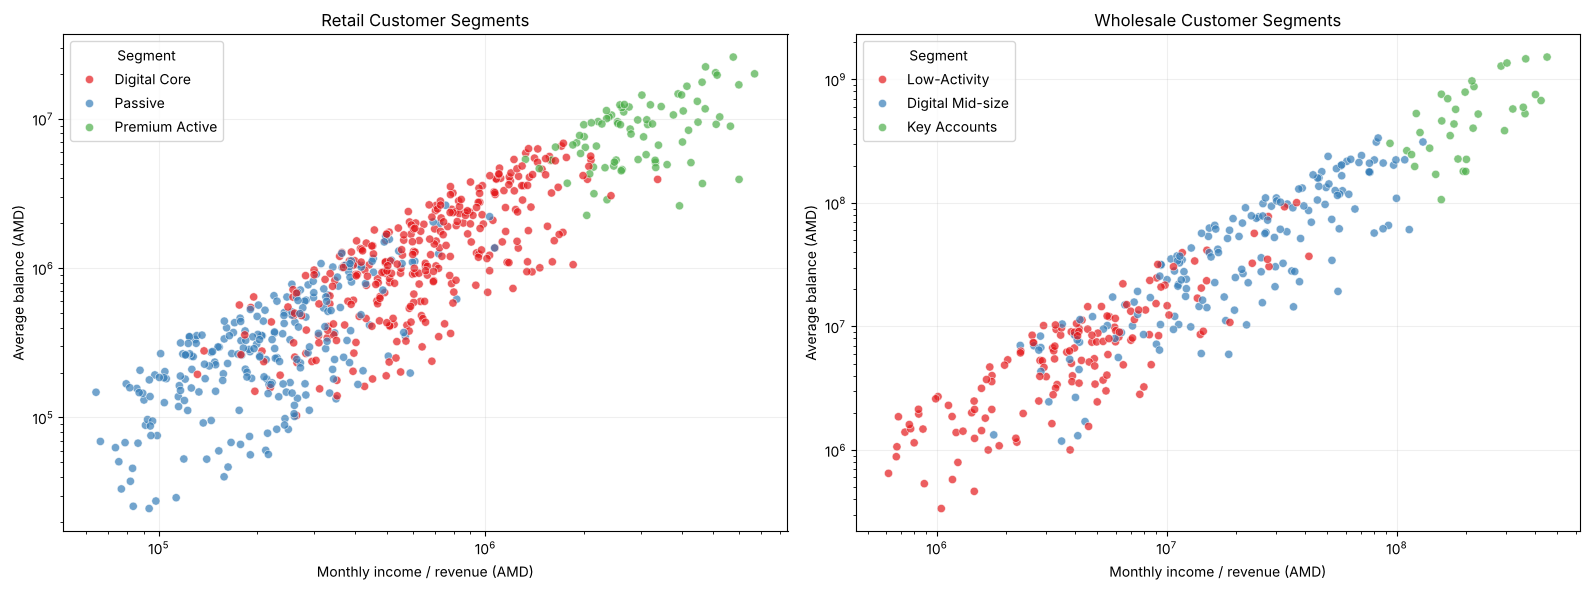

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
for ax, d, title in [(axes[0], retail, "Retail Customer Segments"),
                     (axes[1], wholesale, "Wholesale Customer Segments")]:
    sns.scatterplot(data=d, x="monthly_income_or_revenue_amd", y="average_balance_amd",
                    hue="Segment", palette="Set1", alpha=0.7, s=35, ax=ax)
    ax.set_title(title)
    ax.set_xlabel("Monthly income / revenue (AMD)")
    ax.set_ylabel("Average balance (AMD)")
    ax.set_xscale("log"); ax.set_yscale("log")
    ax.grid(True, alpha=0.2)
plt.tight_layout()
plt.show()

**What makes the groups different** (numbers from the tables above)

| Segment | Retail | Wholesale |
|---|---|---|
| **Top group** (Premium Active / Key Accounts) | 12% of customers, **50%** of 90-day revenue; about 62 transactions per month, 3.1 products | 10% of customers, **58%** of 90-day revenue; about 182 transactions per month, 3.1 products |
| **Digital Core / Digital Mid-size** | 49% of customers, **42%** of revenue; about 81% digital transactions | 48% of customers, **37%** of revenue; about 81% digital transactions |
| **Passive / Low-Activity** | 39% of customers, **8%** of revenue; about 8 transactions per month, 1.7 products, 32% digital | 43% of customers, **5%** of revenue; about 20 transactions per month, 1.9 products, 36% digital |

- The top group is small but brings in about half of the revenue or more. Losing these customers would be costly.
- Past campaign response was highest in the Premium Active group for Retail (28.7%) and in the Digital Mid-size group for Wholesale (24.6%). The passive groups responded least (9.6% Retail, 12.8% Wholesale).

## Part 4. Marketing analytics

For each segment: who the customers are, what product or service may interest them, how to approach them, one campaign idea, and one KPI. The past response numbers come from the `last_campaign_response` column. The product ideas are guesses to test in a small pilot, not proven results.

| Segment | Who they are | Product / service idea | How to approach | Campaign idea | KPI (past response) |
|---|---|---|---|---|---|
| **Premium Active** (Retail)<br>**Key Accounts** (Wholesale) | Retail: 80 customers (12%), about 3.2M AMD income, 9.1M balance, 50% of revenue.<br>Wholesale: 34 customers (10%), about 222M AMD revenue per month, 58% of revenue | Retail: savings, deposits, cards.<br>Wholesale: business payments and cash-flow tools | Personal manager and individual offers | Personal contact and a service plan to keep these customers | Retention rate; 90-day revenue per customer<br>(28.7% Retail, 17.6% Wholesale) |
| **Digital Core** (Retail)<br>**Digital Mid-size** (Wholesale) | Retail: 319 customers (49%), about 81% digital transactions, 42% of revenue.<br>Wholesale: 167 customers (48%), about 81% digital, 37% of revenue | Retail: loans, deposits and cards opened in the app.<br>Wholesale: automatic payments and digital payment tools | Digital channels: banners and notifications in the app, e-mail | Offer related products in the banking app with a simple sign-up | Product activation rate; products per customer<br>(20.1% Retail, 24.6% Wholesale) |
| **Passive** (Retail)<br>**Low-Activity** (Wholesale) | Retail: 251 customers (39%), about 8 transactions per month, 8% of revenue.<br>Wholesale: 149 customers (43%), about 20 transactions per month, 5% of revenue | Simple everyday payments in the mobile app | Low-cost messages with a small incentive (for example cashback); this group brings little revenue, so the cost should stay low | Encourage the first digital transaction | Share of customers with a digital transaction within 30 days<br>(9.6% Retail, 12.8% Wholesale) |

**How to check if a campaign works:** measure the KPI before the campaign, run the campaign on part of the segment, compare it with a similar group that did not get it, and expand only if the result is good. The analysis does not prove that the campaigns will work.

## Limitations and choices

The cell below tests a log transformation, which reduces the effect of very large values, and compares the result with my original groups.

In [13]:
# Robustness check: the same K-Means on log-transformed features
from sklearn.metrics import adjusted_rand_score

for name, d, X_scaled in [("Retail", retail, X_retail_scaled), ("Wholesale", wholesale, X_wholesale_scaled)]:
    X_log = StandardScaler().fit_transform(np.log1p(d[features]))
    log_scores = [silhouette_score(X_log, KMeans(k, random_state=42, n_init=10).fit_predict(X_log)) for k in k_values]
    labels_log = KMeans(3, random_state=42, n_init=10).fit_predict(X_log)
    ari = adjusted_rand_score(d["Cluster"], labels_log)
    print(f"{name}: log-scale Silhouette for k=2..5 = {[round(s, 3) for s in log_scores]}; agreement with original k=3 clusters (ARI) = {ari:.2f}")

Retail: log-scale Silhouette for k=2..5 = [0.357, 0.283, 0.276, 0.275]; agreement with original k=3 clusters (ARI) = 0.47
Wholesale: log-scale Silhouette for k=2..5 = [0.357, 0.271, 0.269, 0.276]; agreement with original k=3 clusters (ARI) = 0.36


- **Why 3 groups:** the Silhouette Score is higher with 2 groups, but I chose 3 on my mentor's advice to get a separate digital group. With 3 groups the score is around 0.33.
- **The results are affected by customer size:** the data is strongly skewed. The log transformation did not improve the Silhouette Score and changed the group assignments, so customer size still has an effect on the groups.
- **Past campaign response only describes previous results.** It does not guarantee that a new campaign will get the same response.
- **Revenue numbers** come from `next_90d_revenue_amd` in the dataset. I did not forecast them.
- The dataset has 1,000 synthetic customers, so results may differ from real bank data.